# SWYNEX Internship | Task 2: Exploratory Data Analysis
**Dataset:** IBM Telco Customer Churn, prepared in Task 1 (`SWYNEX-Data-Preparation`): 7,043 customers, 21 columns, 0 missing values.
**Business question:** Which customers are likely to cancel, and what should the business and a future model do about it?
**Target:** `churn` (1 = customer left in the last month).

**Contents:** 1. Setup · 2. Data overview · 3. Data quality · 4. Target · 5. Univariate · 6. Churn drivers · 7. Correlation · 8. Statistical validation · 9. Controlling for confounders · 10. High-risk segment · 11. Predictive-signal check · 12. Key insights · 13. Recommendations

## Executive summary

**Churn is 26.5% (1,869 of 7,043 customers). It is concentrated in identifiable segments and it is predictable.**

- **Three drivers survive statistical controls** (logistic regression adjusting for all other features): contract term (two-year customers have 74% lower odds of churning than month-to-month), fiber optic service (66% higher odds than DSL) and tenure (about 31% lower odds for every extra year).
- **One segment stands out:** month-to-month + fiber optic + electronic check customers are **18.6% of the base but 42.2% of all churners** (60.4% churn rate; 71.2% when tenure is 12 months or less) and account for **49% of lost monthly revenue**.
- **Protective factors:** online security (37% lower odds) and tech support (32% lower odds). **Risk factors:** paperless billing (+45%), electronic check vs card (+55%), senior citizens (+28%).
- **No effect:** gender and phone service. Partner status loses significance once other features are controlled for.
- **The signal is usable:** a plain logistic regression on these features reaches **ROC-AUC 0.84 and PR-AUC 0.65** (chance level 0.27) in 5-fold cross-validation, and the top 20% of customers by predicted risk contain **51% of all churners**.
- **Actions:** move month-to-month customers to annual terms, strengthen the first six months, investigate the fiber experience, pilot security and support bundles, and promote autopay.

*All figures below are reproduced by the code in this notebook. Findings are associations from a single snapshot, not proof of cause.*

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
import sys; sys.path.insert(0, str(ROOT))
from src.eda_utils import wilson_ci, cramers_v, rate_table
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
PAL = {0: "#4C78A8", 1: "#E4572E"}   # 0 = retained, 1 = churned

def save(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=150, bbox_inches="tight"); plt.show()

df = pd.read_csv(ROOT / "data" / "telco_churn_clean.csv")
df["contract"] = pd.Categorical(df["contract"], ["Month-to-month", "One year", "Two year"], ordered=True)
ADDONS = ["online_security","online_backup","device_protection","tech_support","streaming_tv","streaming_movies"]
NUM = ["tenure","monthly_charges","total_charges"]

## 2. Data overview

In [2]:
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 7,043   Columns: 21


,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,7590-VHVEG,Female,0,1,0,1,0,0,DSL,0,...,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,0,0,34,1,0,DSL,1,...,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,0,0,2,1,0,DSL,1,...,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,0,0,45,0,0,DSL,1,...,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,0,0,2,1,0,Fiber optic,0,...,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
senior_citizen,7043.0,0.16,0.37,0.00,0.00,0.00,0.00,1.00
partner,7043.0,0.48,0.50,0.00,0.00,0.00,1.00,1.00
dependents,7043.0,0.30,0.46,0.00,0.00,0.00,1.00,1.00
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
phone_service,7043.0,0.90,0.30,0.00,1.00,1.00,1.00,1.00
multiple_lines,7043.0,0.42,0.49,0.00,0.00,0.00,1.00,1.00
online_security,7043.0,0.29,0.45,0.00,0.00,0.00,1.00,1.00
online_backup,7043.0,0.34,0.48,0.00,0.00,0.00,1.00,1.00
device_protection,7043.0,0.34,0.48,0.00,0.00,0.00,1.00,1.00
tech_support,7043.0,0.29,0.45,0.00,0.00,0.00,1.00,1.00


## 3. Data quality checks

In [4]:
checks = pd.Series({
    "Missing cells": int(df.isna().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Duplicate customer_id": int(df.customer_id.duplicated().sum()),
    "Customers with tenure = 0 (not yet billed)": int((df.tenure == 0).sum()),
    "Rows where total_charges deviates >50% from tenure x monthly_charges": int((((df.total_charges - df.tenure*df.monthly_charges).abs()) / (df.tenure*df.monthly_charges).replace(0, np.nan) > 0.5).sum()),
})
print(checks.to_string())

# Outliers (IQR rule) on numeric columns
rows = []
for c in NUM:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    rows.append((c, int(((df[c] < q1-1.5*iqr) | (df[c] > q3+1.5*iqr)).sum()), round(df[c].skew(), 2)))
pd.DataFrame(rows, columns=["column", "IQR outliers", "skewness"])

Missing cells                                                            0
Duplicate rows                                                           0
Duplicate customer_id                                                    0
Customers with tenure = 0 (not yet billed)                              11
Rows where total_charges deviates >50% from tenure x monthly_charges     2


,column,IQR outliers,skewness
0,tenure,0,0.24
1,monthly_charges,0,-0.22
2,total_charges,0,0.96


**Takeaway:** the file is clean and unique per customer. No outliers by the IQR rule, and only `total_charges` is notably right-skewed (0.96). The 11 `tenure = 0` customers are brand-new accounts (all retained), so they carry no churn signal but are valid rows.

## 4. Target variable: class balance

Churned: 1,869 of 7,043  (26.5%).  Imbalance ratio retained:churned = 2.8 : 1


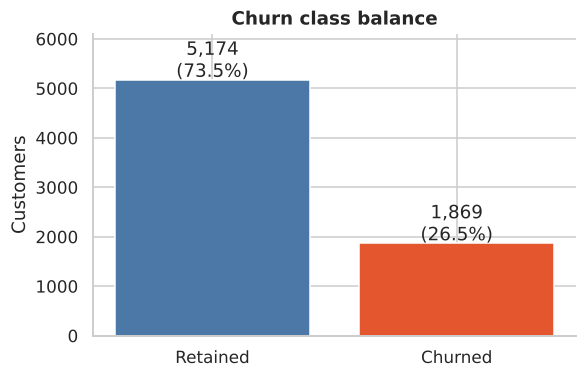

In [5]:
rate = df.churn.mean()
print(f"Churned: {df.churn.sum():,} of {len(df):,}  ({rate:.1%}).  Imbalance ratio retained:churned = {(1-rate)/rate:.1f} : 1")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
counts = df.churn.map({0: "Retained", 1: "Churned"}).value_counts()
ax.bar(counts.index, counts.values, color=[PAL[0], PAL[1]])
for i, v in enumerate(counts.values): ax.text(i, v + 60, f"{v:,}\n({v/len(df):.1%})", ha="center")
ax.set_ylim(0, counts.max()*1.18); ax.set_title("Churn class balance"); ax.set_ylabel("Customers")
save("01_class_balance.png")

## 5. Univariate analysis: numeric features

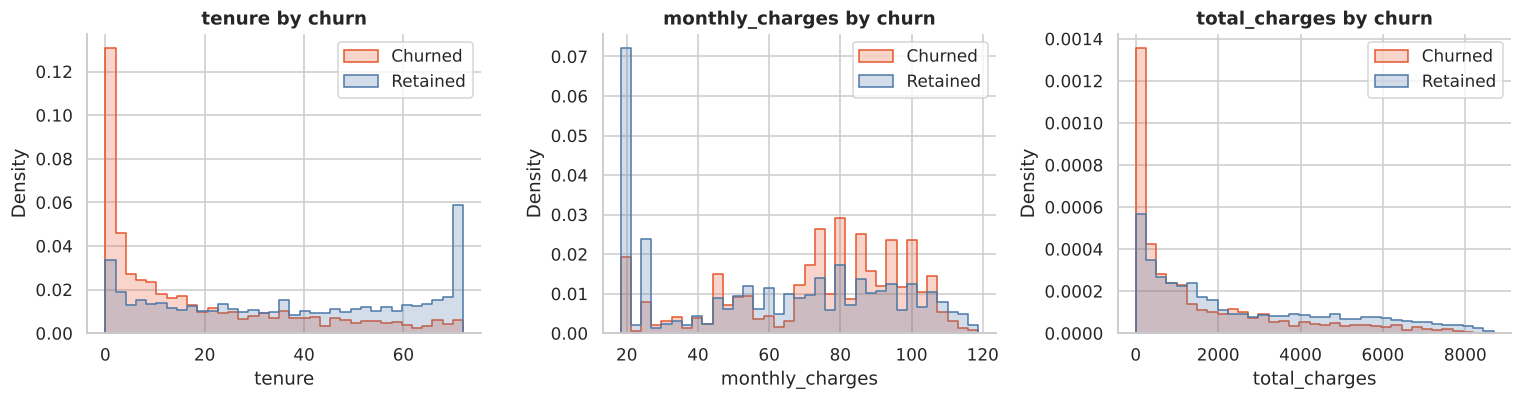

      tenure        monthly_charges        total_charges        
        mean median            mean median          mean  median
churn                                                           
0       37.6   38.0            61.3   64.4        2549.9  1679.5
1       18.0   10.0            74.4   79.6        1531.8   703.6


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axes, NUM):
    sns.histplot(data=df, x=c, hue="churn", palette=PAL, bins=35, stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(f"{c} by churn")
    ax.legend(["Churned", "Retained"], title="")
save("02_numeric_distributions.png")

print(df.groupby("churn")[NUM].agg(["mean", "median"]).round(1).to_string())

The retained group is bimodal in `tenure` (new customers and long-standing loyal ones), while churners cluster at very short tenure. `monthly_charges` shows a dip around $25 and a heavy mass at $70 to $100, where most churners sit.

## 6. Bivariate analysis: what separates churners from retained customers?

### 6.1 Contract type and internet service

contract
Month-to-month    42.7
One year          11.3
Two year           2.8 
Chi-square p-value: 5.86e-258
Month-to-month: 55.0% of customers, 88.6% of all churners

Churn rate by contract x internet service
 internet_service   DSL  Fiber optic    No
contract                                 
Month-to-month    32.2         54.6  18.9
One year           9.3         19.3   2.5
Two year           1.9          7.2   0.8


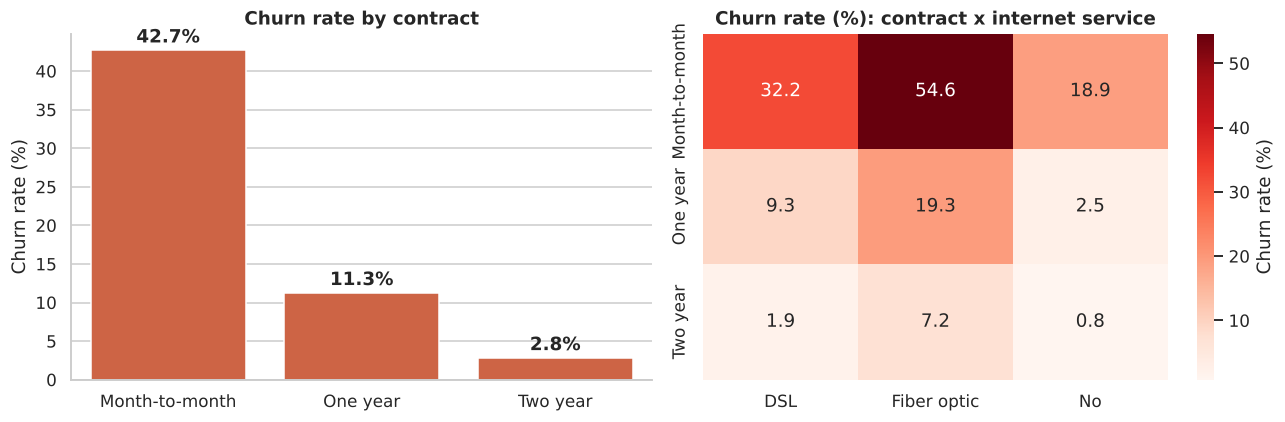

In [7]:
by_contract = df.groupby("contract", observed=True).churn.mean()
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df.contract, df.churn))
print(by_contract.mul(100).round(1).to_string(), f"\nChi-square p-value: {p:.2e}")
m2m = df[df.contract == "Month-to-month"]
print(f"Month-to-month: {len(m2m)/len(df):.1%} of customers, {m2m.churn.sum()/df.churn.sum():.1%} of all churners")

pivot = df.pivot_table(index="contract", columns="internet_service", values="churn", aggfunc="mean", observed=True)
print("\nChurn rate by contract x internet service\n", pivot.mul(100).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=by_contract.index.astype(str), y=by_contract.values*100, color="#E4572E", ax=axes[0])
for i, v in enumerate(by_contract.values): axes[0].text(i, v*100+1, f"{v:.1%}", ha="center", fontweight="bold")
axes[0].set_title("Churn rate by contract"); axes[0].set_ylabel("Churn rate (%)"); axes[0].set_xlabel("")
sns.heatmap(pivot*100, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=axes[1])
axes[1].set_title("Churn rate (%): contract x internet service"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
save("03_contract_internet.png")

### 6.2 Tenure

             mean  count
tenure_band             
0-6          52.9   1481
7-12         35.9    705
13-24        28.7   1024
25-48        20.4   1594
49-72         9.5   2239


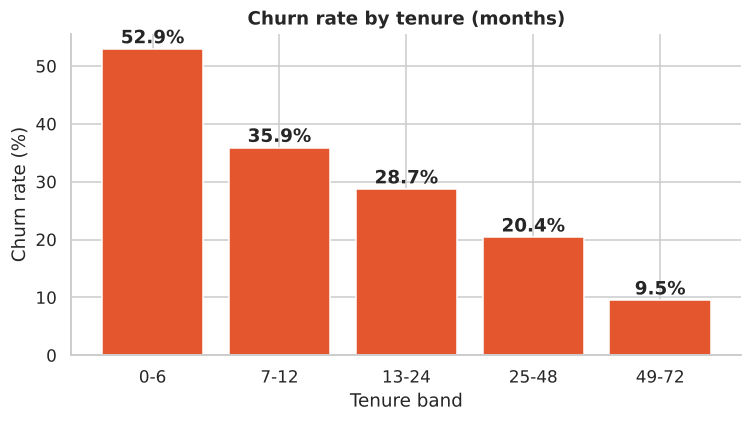

In [8]:
df["tenure_band"] = pd.cut(df.tenure, [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
tb = df.groupby("tenure_band", observed=True).churn.agg(["mean", "count"])
print(tb.assign(mean=lambda d: (d["mean"]*100).round(1)).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(tb.index.astype(str), tb["mean"]*100, color="#E4572E")
for i, v in enumerate(tb["mean"]): ax.text(i, v*100+1, f"{v:.1%}", ha="center", fontweight="bold")
ax.set_title("Churn rate by tenure (months)"); ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Tenure band")
save("04_tenure_churn.png")

### 6.3 Support add-ons (internet customers only)

                   Without  With  Gap (pts)
Online Security       41.8  14.6       27.2
Tech Support          41.6  15.2       26.4
Online Backup         39.9  21.5       18.4
Device Protection     39.1  22.5       16.6
Streaming Movies      33.7  29.9        3.8
Streaming Tv          33.5  30.1        3.4


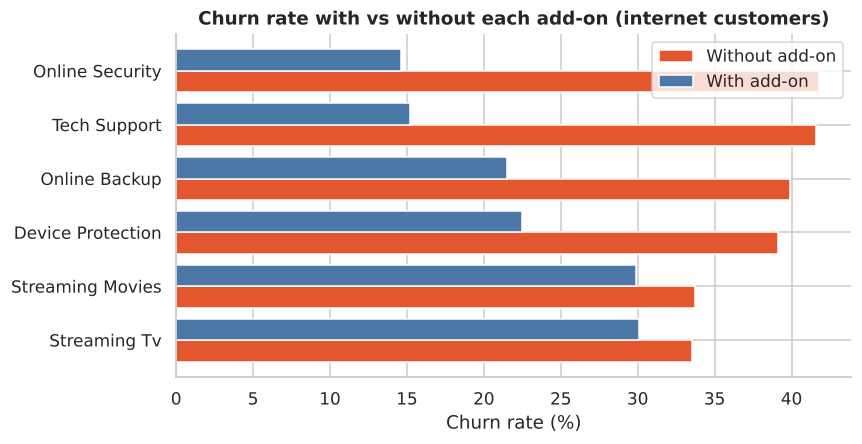

In [9]:
net = df[df.internet_service != "No"]
addon_rates = pd.DataFrame({
    "Without": [net[net[a] == 0].churn.mean() for a in ADDONS],
    "With":    [net[net[a] == 1].churn.mean() for a in ADDONS],
}, index=[a.replace("_", " ").title() for a in ADDONS]).mul(100).round(1)
addon_rates["Gap (pts)"] = (addon_rates.Without - addon_rates.With).round(1)
print(addon_rates.sort_values("Gap (pts)", ascending=False).to_string())

order = addon_rates.sort_values("Gap (pts)").index
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(order))
ax.barh(y-0.2, addon_rates.loc[order, "Without"], 0.4, color="#E4572E", label="Without add-on")
ax.barh(y+0.2, addon_rates.loc[order, "With"], 0.4, color="#4C78A8", label="With add-on")
ax.set_yticks(y); ax.set_yticklabels(order); ax.set_xlabel("Churn rate (%)"); ax.legend()
ax.set_title("Churn rate with vs without each add-on (internet customers)")
save("05_addons.png")

### 6.4 Payment method and billing

payment_method
Credit card (automatic)      15.2
Bank transfer (automatic)    16.7
Mailed check                 19.1
Electronic check             45.3

Paperless billing: {0: 16.3, 1: 33.6}


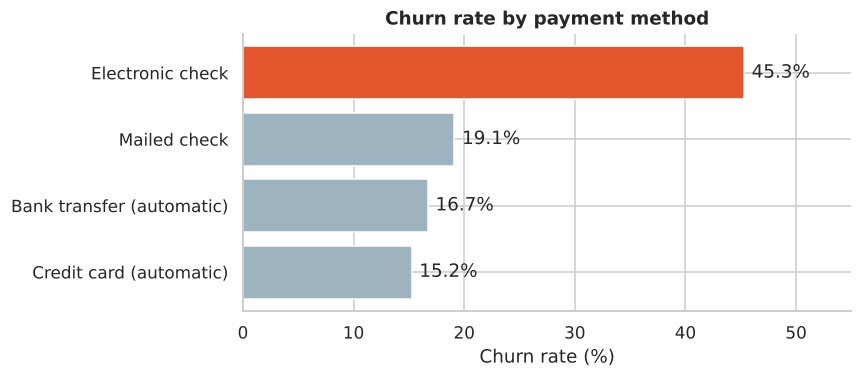

In [10]:
pay = df.groupby("payment_method").churn.mean().sort_values()
print(pay.mul(100).round(1).to_string())
print("\nPaperless billing:", df.groupby("paperless_billing").churn.mean().mul(100).round(1).to_dict())

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = ["#E4572E" if v == pay.max() else "#9DB4C0" for v in pay.values]
ax.barh(pay.index, pay.values*100, color=colors)
for i, v in enumerate(pay.values): ax.text(v*100+0.7, i, f"{v:.1%}", va="center")
ax.set_xlabel("Churn rate (%)"); ax.set_title("Churn rate by payment method"); ax.set_xlim(0, 55)
save("06_payment_method.png")

### 6.5 Price sensitivity and revenue at risk

charge_quintile
Q1 (lowest)      9.2
Q2              25.0
Q3              29.8
Q4              36.1
Q5 (highest)    32.8

Monthly recurring revenue lost to churners: $139,131 of $456,117  (30.5%)
Mean monthly bill: churned $74.44 vs retained $61.27


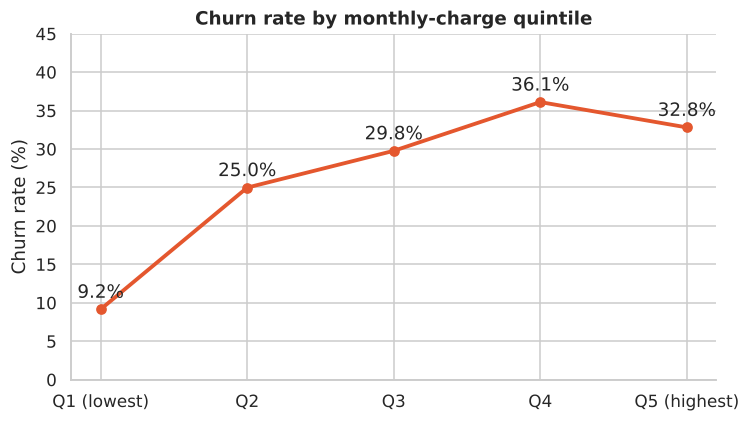

In [11]:
df["charge_quintile"] = pd.qcut(df.monthly_charges, 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
cq = df.groupby("charge_quintile", observed=True).churn.mean()
print(cq.mul(100).round(1).to_string())

at_risk = df.loc[df.churn == 1, "monthly_charges"].sum(); total = df.monthly_charges.sum()
print(f"\nMonthly recurring revenue lost to churners: ${at_risk:,.0f} of ${total:,.0f}  ({at_risk/total:.1%})")
print(f"Mean monthly bill: churned ${df[df.churn==1].monthly_charges.mean():.2f} vs retained ${df[df.churn==0].monthly_charges.mean():.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cq.index.astype(str), cq.values*100, marker="o", color="#E4572E", lw=2.5)
for i, v in enumerate(cq.values): ax.text(i, v*100+1.5, f"{v:.1%}", ha="center")
ax.set_ylim(0, 45); ax.set_ylabel("Churn rate (%)"); ax.set_title("Churn rate by monthly-charge quintile")
save("07_price_quintile.png")

### 6.6 Demographics

In [12]:
demo = {}
for c in ["gender", "senior_citizen", "partner", "dependents"]:
    for k, v in df.groupby(c).churn.mean().items(): demo[f"{c} = {k}"] = round(v*100, 1)
print(pd.Series(demo).to_string())
print("\nGender chi-square p-value:", f"{stats.chi2_contingency(pd.crosstab(df.gender, df.churn))[1]:.3f}")

gender = Female       26.9
gender = Male         26.2
senior_citizen = 0    23.6
senior_citizen = 1    41.7
partner = 0           33.0
partner = 1           19.7
dependents = 0        31.3
dependents = 1        15.5

Gender chi-square p-value: 0.487


## 7. Correlation analysis

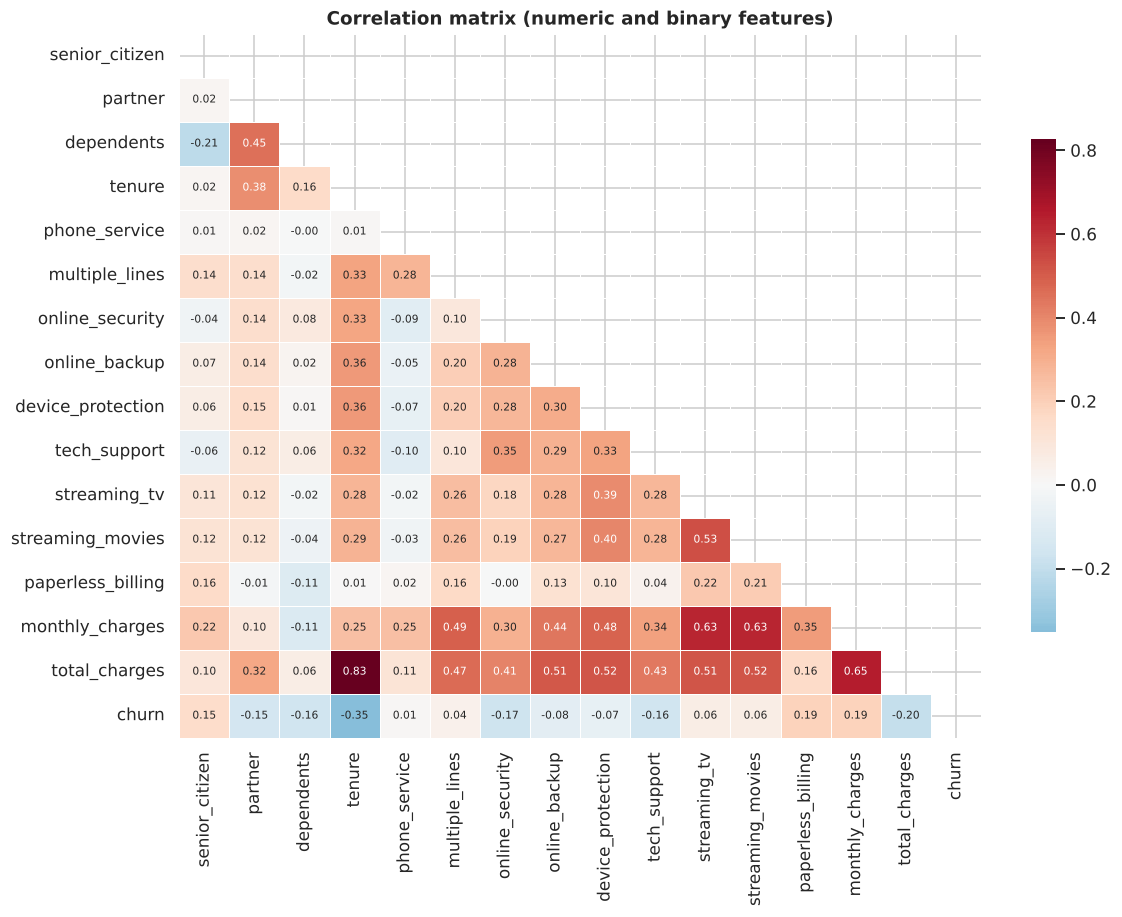

tenure              -0.352
total_charges       -0.198
online_security     -0.171
tech_support        -0.165
dependents          -0.164
partner             -0.150
online_backup       -0.082
device_protection   -0.066
phone_service        0.012
multiple_lines       0.040
streaming_movies     0.061
streaming_tv         0.063
senior_citizen       0.151
paperless_billing    0.192
monthly_charges      0.193

tenure vs total_charges correlation: 0.83


In [13]:
num_cols = df.select_dtypes("number").columns.drop("tenure_band", errors="ignore")
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=.4, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Correlation matrix (numeric and binary features)")
save("08_correlation_heatmap.png")

print(corr["churn"].drop("churn").sort_values().round(3).to_string())
print(f"\ntenure vs total_charges correlation: {corr.loc['tenure','total_charges']:.2f}")

## 8. Statistical validation
Descriptive differences can be noise. This section quantifies **effect size** (Cramér's V for categorical features, rank-biserial correlation for numeric ones) and **uncertainty** (Wilson 95% confidence intervals).
Cramér's V convention: below 0.1 negligible, 0.1 to 0.3 small, 0.3 and above medium or larger.

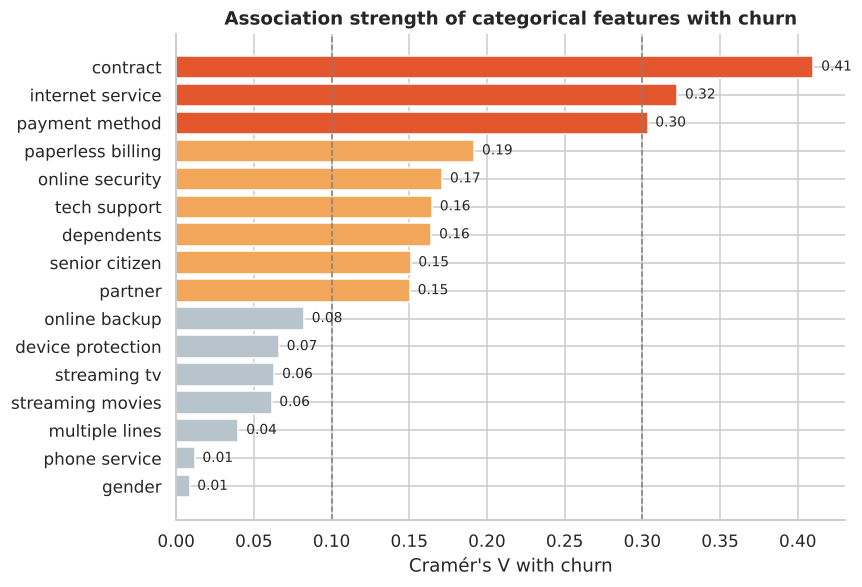

numeric feature Mann-Whitney p  rank-biserial r (churned vs retained)
         tenure       2.4e-208                                  -0.48
monthly_charges        3.3e-54                                   0.24
  total_charges        5.7e-83                                  -0.30


In [14]:
CAT = ["contract","internet_service","payment_method","paperless_billing","online_security","tech_support","dependents","senior_citizen","partner","online_backup","device_protection","streaming_tv","streaming_movies","multiple_lines","phone_service","gender"]
cv = pd.Series({c: cramers_v(df[c], df.churn) for c in CAT}).sort_values()
colors = ["#E4572E" if v >= .3 else "#F2A65A" if v >= .1 else "#B8C4CC" for v in cv.values]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh([c.replace("_", " ") for c in cv.index], cv.values, color=colors)
for i, v in enumerate(cv.values): ax.text(v + .005, i, f"{v:.2f}", va="center", fontsize=9)
ax.axvline(.1, ls="--", c="grey", lw=1); ax.axvline(.3, ls="--", c="grey", lw=1)
ax.set_xlabel("Cramér's V with churn"); ax.set_title("Association strength of categorical features with churn")
save("09_association_strength.png")

rows = []
for c in NUM:
    a, b = df.loc[df.churn == 1, c], df.loc[df.churn == 0, c]
    u = stats.mannwhitneyu(a, b)
    rows.append((c, f"{u.pvalue:.1e}", round(2*u.statistic/(len(a)*len(b)) - 1, 2)))
print(pd.DataFrame(rows, columns=["numeric feature", "Mann-Whitney p", "rank-biserial r (churned vs retained)"]).to_string(index=False))

Contract, internet service and payment method have medium-sized associations (V = 0.41, 0.32, 0.30). Gender (0.01) and phone service (0.01) are negligible. All three numeric features differ significantly between churners and retained customers, with `tenure` showing the largest effect.

                                              n  churn_rate  ci_low  ci_high
contract: Month-to-month                   3875        42.7    41.2     44.3
contract: One year                         1473        11.3     9.8     13.0
contract: Two year                         1695         2.8     2.1      3.7
internet service: DSL                      2421        19.0    17.4     20.6
internet service: Fiber optic              3096        41.9    40.2     43.6
internet service: No                       1526         7.4     6.2      8.8
payment method: Bank transfer (automatic)  1544        16.7    14.9     18.7
payment method: Credit card (automatic)    1522        15.2    13.5     17.1
payment method: Electronic check           2365        45.3    43.3     47.3
payment method: Mailed check               1612        19.1    17.3     21.1
tenure band: 0-6                           1481        52.9    50.4     55.5
tenure band: 13-24                         1024        28.7    26.0     31.6

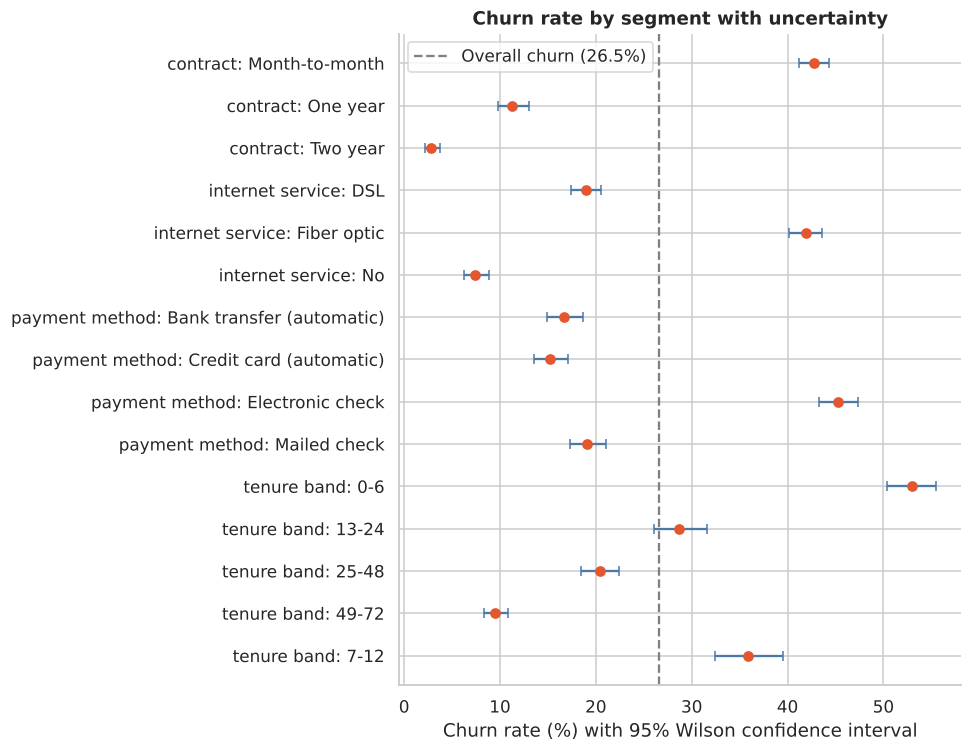

In [15]:
parts = []
for col in ["contract", "internet_service", "payment_method", "tenure_band"]:
    t = rate_table(df.assign(tenure_band=df.tenure_band.astype(str)), col)
    t.index = [f"{col.replace('_', ' ')}: {i}" for i in t.index]; parts.append(t)
ci = pd.concat(parts)
print(ci.assign(**{c: (ci[c]*100).round(1) for c in ["churn_rate", "ci_low", "ci_high"]}).to_string())

fig, ax = plt.subplots(figsize=(9, 7))
y_pos = np.arange(len(ci))[::-1]
ax.errorbar(ci.churn_rate*100, y_pos, xerr=[(ci.churn_rate-ci.ci_low)*100, (ci.ci_high-ci.churn_rate)*100], fmt="o", color="#E4572E", ecolor="#4C78A8", capsize=3)
ax.axvline(df.churn.mean()*100, ls="--", c="grey", label=f"Overall churn ({df.churn.mean():.1%})")
ax.set_yticks(y_pos); ax.set_yticklabels(ci.index); ax.set_xlabel("Churn rate (%) with 95% Wilson confidence interval"); ax.legend()
ax.set_title("Churn rate by segment with uncertainty")
save("10_segment_confidence_intervals.png")

Intervals are narrow for the large segments, so the rankings are not sampling noise. For example, month-to-month churn is 42.7% (95% CI about 41.2% to 44.3%) against 2.8% for two-year contracts.

## 9. Controlling for confounders
Contract, tenure, internet type and price are all related to one another, so a raw gap can be inherited from another variable. A multivariable **logistic regression** estimates each feature's effect while holding the others fixed. Odds ratio (OR) above 1 means higher churn odds; below 1 means lower.

                                                                        odds_ratio  ci_low  ci_high       p
Contract: Two year (vs Month-to-month)                                        0.26    0.19     0.37  <0.001
Internet service: No (vs DSL)                                                 0.46    0.34     0.63  <0.001
Contract: One year (vs Month-to-month)                                        0.52    0.42     0.63  <0.001
Online security (yes vs no)                                                   0.63    0.54     0.75  <0.001
Tech support (yes vs no)                                                      0.68    0.57     0.81  <0.001
Tenure (per +12 months)                                                       0.69    0.65     0.72  <0.001
Dependents (yes vs no)                                                        0.83    0.70     0.99   0.037
Gender: Male (vs Female)                                                      0.98    0.86     1.11   0.703
Partner (yes vs no)         

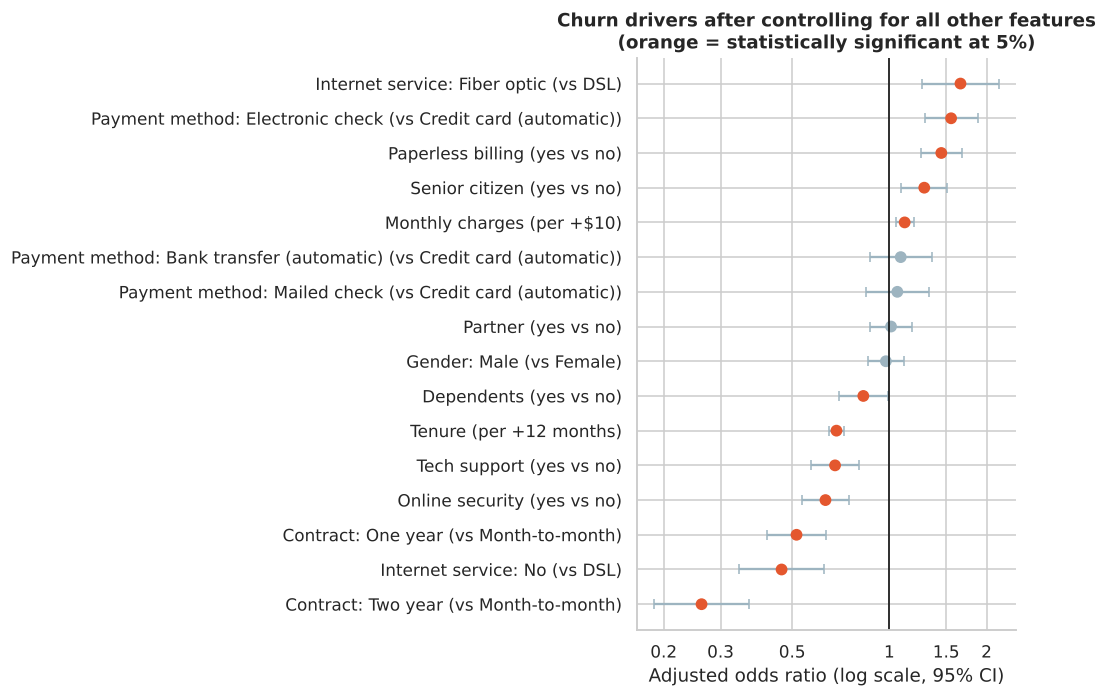

In [16]:
formula = ("churn ~ C(contract, Treatment('Month-to-month')) + C(internet_service, Treatment('DSL')) + "
           "C(payment_method, Treatment('Credit card (automatic)')) + tenure_12m + charges_10 + senior_citizen + partner + "
           "dependents + online_security + tech_support + paperless_billing + gender")
dfm = df.assign(tenure_12m=df.tenure/12, charges_10=df.monthly_charges/10)
model = smf.logit(formula, data=dfm).fit(disp=0)

def pretty(n):
    if n.startswith("C("):
        var = n.split("(")[1].split(",")[0]; level = n.split("[T.")[1].rstrip("]"); ref = n.split("Treatment('")[1].split("'")[0]
        return f"{var.replace('_', ' ').capitalize()}: {level} (vs {ref})"
    return {"gender[T.Male]": "Gender: Male (vs Female)", "tenure_12m": "Tenure (per +12 months)", "charges_10": "Monthly charges (per +$10)"}.get(n, n.replace("_", " ").capitalize() + " (yes vs no)")

res = pd.DataFrame({"odds_ratio": np.exp(model.params), "ci_low": np.exp(model.conf_int()[0]), "ci_high": np.exp(model.conf_int()[1]), "p": model.pvalues}).drop("Intercept")
res.index = [pretty(i) for i in res.index]
res = res.sort_values("odds_ratio")
print(res.assign(odds_ratio=res.odds_ratio.round(2), ci_low=res.ci_low.round(2), ci_high=res.ci_high.round(2), p=res.p.map(lambda x: "<0.001" if x < .001 else f"{x:.3f}")).to_string())
print(f"\nPseudo R-squared: {model.prsquared:.3f}   n = {int(model.nobs):,}")
print(f"Monthly charges: OR per +$10 = {res.loc['Monthly charges (per +$10)', 'odds_ratio']:.2f}   |   Tenure: OR per +12 months = {res.loc['Tenure (per +12 months)', 'odds_ratio']:.2f}")

fig, ax = plt.subplots(figsize=(9.5, 6.5))
yy = np.arange(len(res))
sig = res.p < .05
ax.errorbar(res.odds_ratio, yy, xerr=[res.odds_ratio-res.ci_low, res.ci_high-res.odds_ratio], fmt="none", ecolor="#9DB4C0", capsize=3, zorder=1)
ax.scatter(res.odds_ratio, yy, c=np.where(sig, "#E4572E", "#9DB4C0"), s=45, zorder=2)
ax.axvline(1, c="black", lw=1); ax.set_xscale("log")
ax.set_xticks([.2, .3, .5, 1, 1.5, 2]); ax.set_xticklabels(["0.2", "0.3", "0.5", "1", "1.5", "2"]); ax.minorticks_off()
ax.set_yticks(yy); ax.set_yticklabels(res.index); ax.set_xlabel("Adjusted odds ratio (log scale, 95% CI)")
ax.set_title("Churn drivers after controlling for all other features\n(orange = statistically significant at 5%)")
save("11_adjusted_odds_ratios.png")

**What survives adjustment:** contract term, fiber optic, tenure, online security, tech support, paperless billing, electronic check and senior citizen all remain significant.
**What does not:** gender (OR 0.98, p = 0.70) and partner status (OR 1.01, p = 0.88). The raw partner gap seen earlier (33.0% vs 19.7%) is explained by other variables. Bank transfer and mailed check do not differ from credit card once other features are controlled (p > 0.4), so the raw payment gap is concentrated in electronic check.

## 10. High-risk segment
The three strongest categorical drivers combine. Which customers sit at the intersection, and how much do they matter?

                                  customers  % of base  churn rate %  % of all churners  monthly revenue lost $
segment                                                                                                        
Month-to-month + Fiber + E-check       1307       18.6          60.4               42.2                 68281.5
  ... and tenure <= 12 months           631        9.0          71.2               24.0                 37166.0
All other customers                    5736       81.4          18.8               57.8                 70849.3
All customers                          7043      100.0          26.5              100.0                139130.8

Segment share of all lost monthly revenue: 49.1%


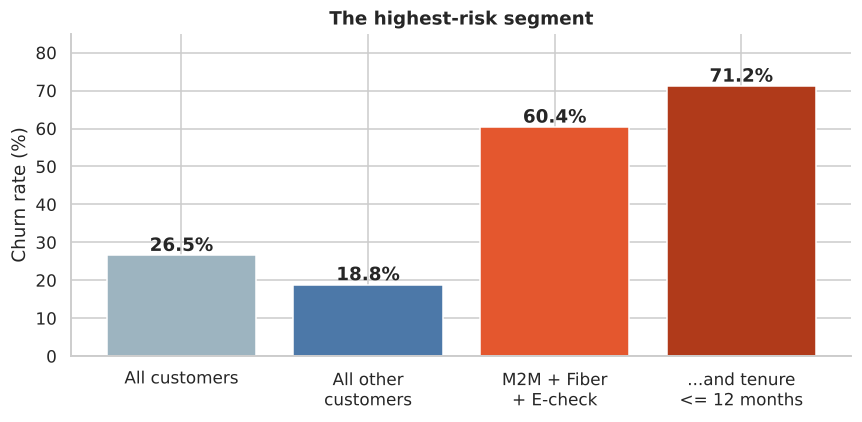

In [17]:
seg = (df.contract == "Month-to-month") & (df.internet_service == "Fiber optic") & (df.payment_method == "Electronic check")
seg_new = seg & (df.tenure <= 12)
def summ(mask, name):
    d = df[mask]
    return {"segment": name, "customers": len(d), "% of base": len(d)/len(df)*100, "churn rate %": d.churn.mean()*100,
            "% of all churners": d.churn.sum()/df.churn.sum()*100, "monthly revenue lost $": d.loc[d.churn == 1, "monthly_charges"].sum()}
seg_tbl = pd.DataFrame([summ(seg, "Month-to-month + Fiber + E-check"), summ(seg_new, "  ... and tenure <= 12 months"),
                        summ(~seg, "All other customers"), summ(pd.Series(True, index=df.index), "All customers")]).set_index("segment")
print(seg_tbl.round(1).to_string())
print(f"\nSegment share of all lost monthly revenue: {seg_tbl.iloc[0]['monthly revenue lost $'] / at_risk:.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
lab = ["All customers", "All other\ncustomers", "M2M + Fiber\n+ E-check", "...and tenure\n<= 12 months"]
val = [seg_tbl.loc["All customers", "churn rate %"], seg_tbl.loc["All other customers", "churn rate %"], seg_tbl.iloc[0]["churn rate %"], seg_tbl.iloc[1]["churn rate %"]]
ax.bar(lab, val, color=["#9DB4C0", "#4C78A8", "#E4572E", "#B03A1A"])
for i, v in enumerate(val): ax.text(i, v+1.2, f"{v:.1f}%", ha="center", fontweight="bold")
ax.set_ylim(0, 85); ax.set_ylabel("Churn rate (%)"); ax.set_title("The highest-risk segment")
save("12_high_risk_segment.png")

## 11. Predictive-signal check
A quick sanity check that the patterns found above carry real predictive power. This is **not** the Task 3 modelling work: a plain logistic regression, default threshold, 5-fold stratified cross-validation, no tuning.

ROC-AUC: 0.843 +/- 0.014
PR-AUC : 0.654 +/- 0.026   (no-skill baseline = 0.265)
Top 20% of customers by predicted risk: churn rate 67.5%, capture 50.8% of all churners


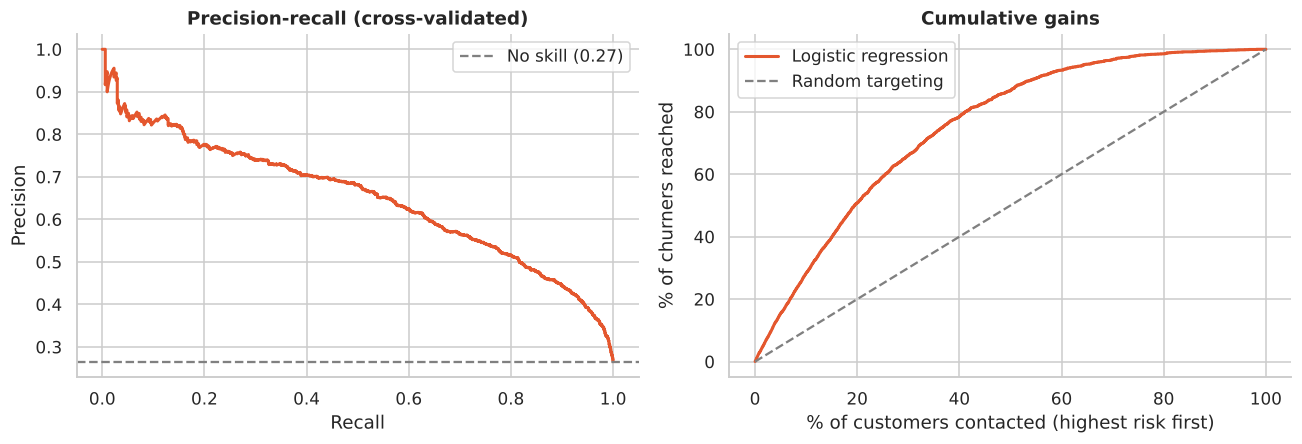

In [18]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import precision_recall_curve

X = df.drop(columns=["customer_id", "churn", "total_charges", "tenure_band", "charge_quintile"]); y = df.churn
cat = X.select_dtypes(exclude="number").columns.tolist(); num = [c for c in X.columns if c not in cat]
pipe = make_pipeline(ColumnTransformer([("cat", OneHotEncoder(drop="first"), cat), ("num", StandardScaler(), num)]), LogisticRegression(max_iter=1000))
cv5 = StratifiedKFold(5, shuffle=True, random_state=42)
sc = cross_validate(pipe, X, y, cv=cv5, scoring=["roc_auc", "average_precision"])
print(f"ROC-AUC: {sc['test_roc_auc'].mean():.3f} +/- {sc['test_roc_auc'].std():.3f}")
print(f"PR-AUC : {sc['test_average_precision'].mean():.3f} +/- {sc['test_average_precision'].std():.3f}   (no-skill baseline = {y.mean():.3f})")

proba = cross_val_predict(pipe, X, y, cv=cv5, method="predict_proba")[:, 1]
order = np.argsort(-proba); k = int(len(y) * .2)
print(f"Top 20% of customers by predicted risk: churn rate {y.values[order][:k].mean():.1%}, capture {y.values[order][:k].sum()/y.sum():.1%} of all churners")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
p_, r_, _ = precision_recall_curve(y, proba)
axes[0].plot(r_, p_, color="#E4572E", lw=2); axes[0].axhline(y.mean(), ls="--", c="grey", label=f"No skill ({y.mean():.2f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Precision-recall (cross-validated)"); axes[0].legend()
frac = np.arange(1, len(y)+1)/len(y); gains = np.cumsum(y.values[order])/y.sum()
axes[1].plot(frac*100, gains*100, color="#E4572E", lw=2, label="Logistic regression"); axes[1].plot([0, 100], [0, 100], "--", c="grey", label="Random targeting")
axes[1].set_xlabel("% of customers contacted (highest risk first)"); axes[1].set_ylabel("% of churners reached"); axes[1].set_title("Cumulative gains"); axes[1].legend()
save("13_baseline_signal.png")

The EDA features carry strong signal: ROC-AUC of about 0.84 and PR-AUC of about 0.65 against a no-skill 0.27. Contacting the top 20% of customers by predicted risk would reach about half of all churners, which is the business case for the modelling task.

## 12. Key insights

Each insight follows **Observation → Evidence → Impact**, and states whether it survives statistical controls.

**1. Contract type is the strongest single driver.**
*Evidence:* month-to-month customers churn at **42.7%**, versus **11.3%** (one year) and **2.8%** (two year); chi-square p < 1e-200, Cramér's V = 0.41 (largest of all features). Month-to-month customers are 55% of the base but **89%** of all churners. *After adjustment:* two-year customers have **74% lower odds** (OR 0.26) than month-to-month.
*Impact:* contract is a must-have model feature, and moving customers to annual terms is the single biggest retention lever.

**2. The first six months are the danger zone.**
*Evidence:* churn is **52.9%** for tenure 0 to 6 months, falling to **9.5%** beyond 48 months. Churners have a median tenure of **10 months** against **38** for retained customers. *After adjustment:* every extra year of tenure cuts churn odds by about **31%** (OR 0.69 per 12 months).
*Impact:* an onboarding and early-life retention programme has the highest return.

**3. Fiber optic customers churn at more than twice the DSL rate, and contract does not explain it away.**
*Evidence:* fiber **41.9%** vs DSL **19.0%**. Within month-to-month contracts **54.6%** vs **32.2%**, and within one-year contracts 19.3% vs 9.3%. *After adjustment:* fiber has **66% higher odds** than DSL (OR 1.66, 95% CI 1.26 to 2.19).
*Impact:* the premium product has a service or price-satisfaction problem worth investigating (outages, pricing, competitor offers).

**4. Online security and tech support go with much lower churn.**
*Evidence:* among internet customers, churn is **41.8%** without online security vs **14.6%** with it, and **41.6%** vs **15.2%** for tech support. Streaming add-ons show almost no gap (3 to 4 points). *After adjustment:* **37%** and **32% lower odds** (OR 0.63 and 0.68).
*Impact:* bundling or discounting these services is a promising retention test. Customers who choose them may already be more engaged, so the effect should be tested, not assumed causal.

**5. Electronic check and paperless billing carry extra risk beyond what other features explain.**
*Evidence:* electronic check churn is **45.3%** vs **15.2% to 19.1%** for other methods; paperless billing **33.6%** vs **16.3%**. *After adjustment:* electronic check keeps **55% higher odds** than credit card (OR 1.55, p < 0.001), paperless billing **45% higher** (OR 1.45). Bank transfer and mailed check do not differ from credit card (p > 0.4).
*Impact:* a large part of the raw payment gap is explained by contract and tenure mix, but a real residual remains. Autopay enrolment is a cheap campaign, and payment method should be a model feature.

**6. Higher-paying customers churn more, and churners carry about 30% of recurring revenue.**
*Evidence:* mean monthly bill is **$74.44** for churners vs **$61.27** for retained. Churn rises from **9.2%** in the lowest price quintile to **36.1%** in the fourth. Churners represent **$139,131 of $456,117** monthly revenue (**30.5%**), above their 26.5% customer share. *After adjustment:* each extra **$10 per month** raises churn odds by about **12%** (OR 1.12, 95% CI 1.05 to 1.19).
*Impact:* churn is a larger revenue problem than the headcount suggests; models should be judged on revenue saved, not accuracy alone.

**7. One segment concentrates the problem.**
*Evidence:* month-to-month + fiber optic + electronic check customers are **18.6%** of the base (1,307 customers) but **42.2%** of all churners, with a **60.4%** churn rate (versus 18.8% for everyone else), rising to **71.2%** when tenure is 12 months or less. They account for **49%** of all lost monthly revenue.
*Impact:* this is the natural first target for a retention campaign and a useful rule-based benchmark for any model.

**8. Gender is not predictive, and partner status is redundant; seniors carry real extra risk.**
*Evidence:* gender churn is 26.9% (F) vs 26.2% (M), not significant (p = 0.49), and still not after adjustment (OR 0.98, p = 0.70). The raw partner gap (33.0% vs 19.7%) disappears after adjustment (OR 1.01, p = 0.88). Senior citizens churn at **41.7%** vs **23.6%** and keep **28% higher odds** (OR 1.28, p = 0.003).
*Impact:* drop `gender` (noise and fairness risk) and treat `partner` as optional; keep `senior_citizen` and `dependents`.

**Data notes for modelling.**
- Class imbalance is **26.5% churn (2.8 : 1)**: use stratified splits and judge with recall, PR-AUC and F1, not accuracy.
- `tenure` and `total_charges` are strongly correlated (r = 0.83), a multicollinearity risk for linear models. `total_charges` is also right-skewed (0.96): consider a log transform or dropping it in favour of `tenure` and `monthly_charges` (done in the check above).
- Only 2 rows show `total_charges` deviating more than 50% from `tenure x monthly_charges`; they are left unchanged.

## 13. Recommendations

**For the business**
1. Target the high-risk segment (month-to-month, fiber, electronic check) first, with contract-upgrade offers.
2. Build an early-life programme for the first six months, when churn is above 50%.
3. Investigate the fiber optic experience (service quality and price perception).
4. Pilot free or discounted online security and tech support for at-risk internet customers, as a controlled test so the effect can be measured.
5. Promote autopay enrolment, especially for electronic-check customers.

**For modelling (next task)**
1. Features to keep: contract, tenure, internet service, payment method, online security, tech support, monthly charges, senior citizen, dependents, paperless billing. Candidate interactions: contract x internet service; tenure band.
2. Drop `gender` and `customer_id`; treat `partner` as optional; resolve the `tenure` / `total_charges` overlap.
3. Baseline to beat: logistic regression with ROC-AUC 0.84 and PR-AUC 0.65 (section 11). Then gradient boosting, stratified k-fold, and a decision threshold tuned against retention-campaign cost.
4. Evaluate by revenue saved as well as recall and precision.

**Limitations:** single static snapshot with no time dimension, so findings are associations rather than causal effects, and drift or leakage cannot be assessed. The retention actions above should be validated with controlled experiments.